In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder


In [6]:
df = sns.load_dataset('titanic')

In [7]:
print("First 5 Rows:")
print(df.head())

First 5 Rows:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [8]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(891, 15)


In [9]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str')


In [10]:
print("\nData Types:")
print(df.dtypes)


Data Types:
survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object


In [11]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [12]:
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    elif df[col].dtype in ['float64', 'int64']:
        df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=['category']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])


In [13]:
print("\nMissing Values After Handling:")
print(df.isnull().sum())



Missing Values After Handling:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
class          0
who            0
adult_male     0
deck           0
embark_town    2
alive          0
alone          0
dtype: int64


In [17]:
le = LabelEncoder()

for col in df.select_dtypes(include=['object']).columns:
    df[col] = le.fit_transform(df[col])

In [18]:
print("\nEncoded Dataset:")
print(df.head())


Encoded Dataset:
   survived  pclass  sex   age  sibsp  parch     fare  embarked  class  who  \
0         0       3    1  22.0      1      0   7.2500         2  Third    1   
1         1       1    0  38.0      1      0  71.2833         0  First    2   
2         1       3    0  26.0      0      0   7.9250         2  Third    2   
3         1       1    0  35.0      1      0  53.1000         2  First    2   
4         0       3    1  35.0      0      0   8.0500         2  Third    1   

   adult_male deck  embark_town  alive  alone  
0        True    C            2      0  False  
1       False    C            0      1  False  
2       False    C            2      1   True  
3       False    C            2      1  False  
4        True    C            2      0   True  


In [19]:
df = sns.load_dataset('titanic')

df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

print("\nFrequency Distribution:")
print(df['sex'].value_counts())
print(df['class'].value_counts())
print(df['embarked'].value_counts())


Frequency Distribution:
sex
male      577
female    314
Name: count, dtype: int64
class
Third     491
First     216
Second    184
Name: count, dtype: int64
embarked
S    646
C    168
Q     77
Name: count, dtype: int64


In [20]:
print("\nPercentage Distribution:")
print(df['sex'].value_counts(normalize=True) * 100)
print(df['class'].value_counts(normalize=True) * 100)
print(df['embarked'].value_counts(normalize=True) * 100)


Percentage Distribution:
sex
male      64.758698
female    35.241302
Name: proportion, dtype: float64
class
Third     55.106622
First     24.242424
Second    20.650954
Name: proportion, dtype: float64
embarked
S    72.502806
C    18.855219
Q     8.641975
Name: proportion, dtype: float64


In [21]:
print("\nMost Common Categories:")
print("Sex:", df['sex'].mode()[0])
print("Class:", df['class'].mode()[0])
print("Embarked:", df['embarked'].mode()[0])


Most Common Categories:
Sex: male
Class: Third
Embarked: S


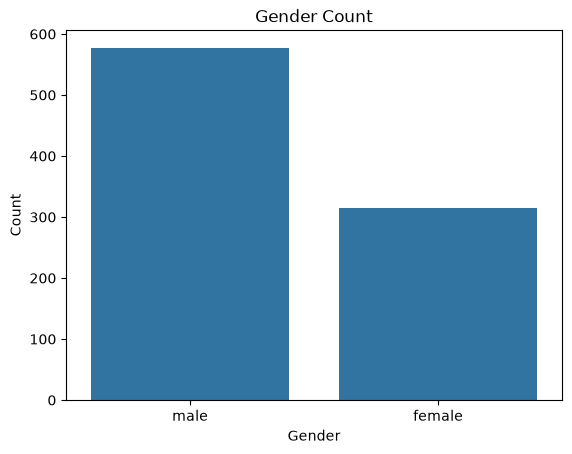

In [22]:
sns.countplot(x='sex', data=df)
plt.title("Gender Count")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

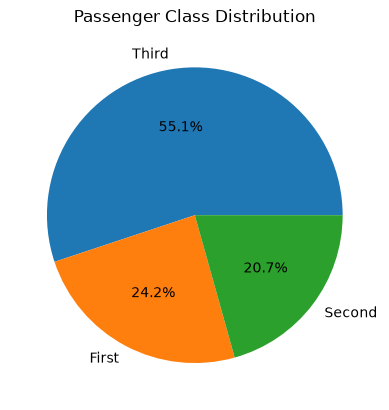

In [23]:
df['class'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title("Passenger Class Distribution")
plt.ylabel("")
plt.show()

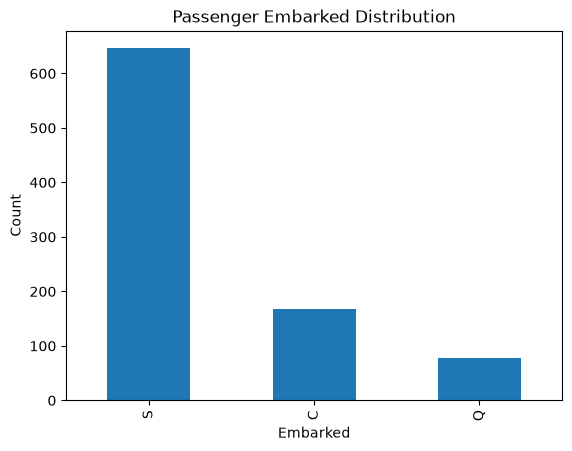

In [24]:
df['embarked'].value_counts().plot(kind='bar')
plt.title("Passenger Embarked Distribution")
plt.xlabel("Embarked")
plt.ylabel("Count")
plt.show()

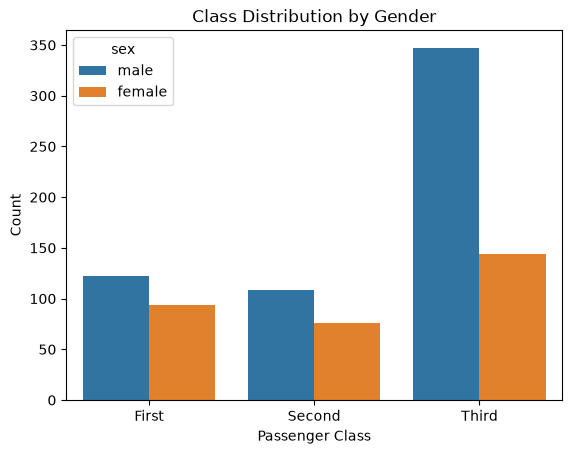

In [25]:
sns.countplot(x='class', hue='sex', data=df)
plt.title("Class Distribution by Gender")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()